In [1]:
pip install opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


## Problem 1: Comparative Edge Detection on Natural Images

### Aim: To apply Sobel, Laplacian, and Canny edge detection techniques to a natural outdoor image and compare their results.

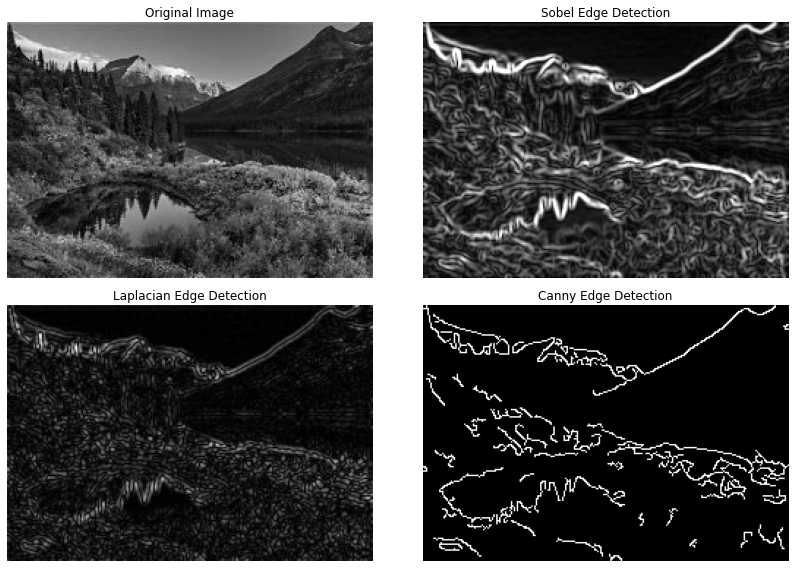

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the natural image in grayscale
img = cv2.imread("natural_image.jpeg", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found. Check the file path.")
    exit()

# Apply Gaussian blur to reduce noise
blurred = cv2.GaussianBlur(img, (5, 5), 0)

# Sobel edge detection
sobel_x = cv2.Sobel(
    blurred, cv2.CV_64F, 1, 0, ksize=3
)
sobel_y = cv2.Sobel(
    blurred, cv2.CV_64F, 0, 1, ksize=3
)

sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

# Laplacian edge detection
laplacian = cv2.Laplacian(
    blurred, cv2.CV_64F, ksize=3
)
laplacian = cv2.convertScaleAbs(laplacian)

# Canny edge detection
canny = cv2.Canny(blurred, 100, 200)

# Display results
images = [
    (img, "Original Image"),
    (sobel, "Sobel Edge Detection"),
    (laplacian, "Laplacian Edge Detection"),
    (canny, "Canny Edge Detection")
]

plt.figure(figsize=(12, 8))

for i, (image, title) in enumerate(images):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


## Problem 2: Noise Sensitivity Experiment

### Aim: To investigate the effects of Gaussian noise and salt-and-pepper noise on Sobel and Laplacian edge detection.

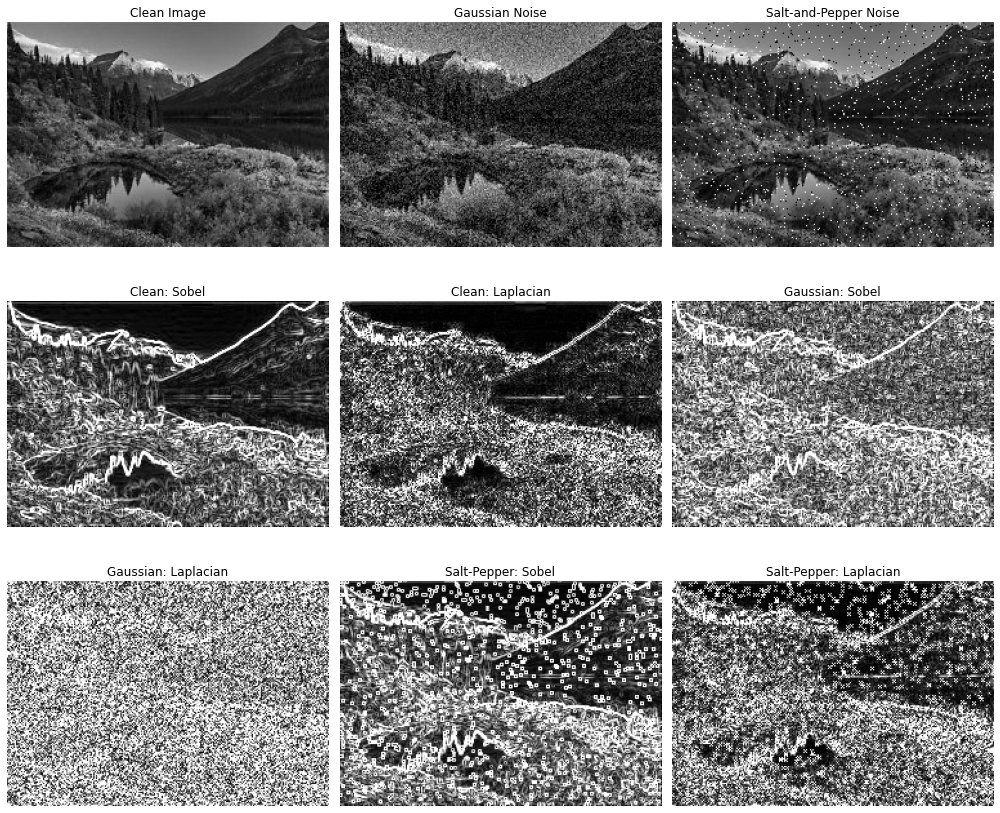

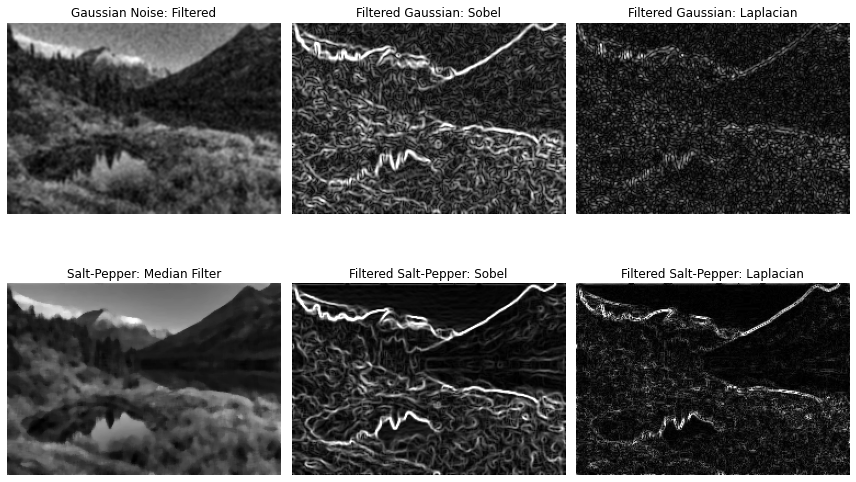

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load a clean grayscale image
img = cv2.imread("natural_image.jpeg", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found. Check the file path.")
    exit()

# 1. Add Gaussian noise
np.random.seed(42)

gaussian_noise = np.random.normal(
    0, 25, img.shape
)

gaussian_img = np.clip(
    img.astype(np.float32) + gaussian_noise,
    0, 255
).astype(np.uint8)

# 2. Add salt-and-pepper noise
sp_img = img.copy()

noise_mask = np.random.random(img.shape)

sp_img[noise_mask < 0.02] = 0
sp_img[(noise_mask >= 0.02) &
       (noise_mask < 0.04)] = 255

# 3. Define edge detection function
def detect_edges(image):
    sobel_x = cv2.Sobel(
        image, cv2.CV_64F, 1, 0, ksize=3
    )
    sobel_y = cv2.Sobel(
        image, cv2.CV_64F, 0, 1, ksize=3
    )

    sobel = cv2.magnitude(sobel_x, sobel_y)
    sobel = cv2.convertScaleAbs(sobel)

    laplacian = cv2.Laplacian(
        image, cv2.CV_64F, ksize=3
    )
    laplacian = cv2.convertScaleAbs(laplacian)

    return sobel, laplacian

# 4. Detect edges in clean and noisy images
clean_sobel, clean_laplacian = detect_edges(img)

gaussian_sobel, gaussian_laplacian = detect_edges(
    gaussian_img
)

sp_sobel, sp_laplacian = detect_edges(sp_img)

# 5. Display the comparison
results = [
    (img, "Clean Image"),
    (gaussian_img, "Gaussian Noise"),
    (sp_img, "Salt-and-Pepper Noise"),
    (clean_sobel, "Clean: Sobel"),
    (clean_laplacian, "Clean: Laplacian"),
    (gaussian_sobel, "Gaussian: Sobel"),
    (gaussian_laplacian, "Gaussian: Laplacian"),
    (sp_sobel, "Salt-Pepper: Sobel"),
    (sp_laplacian, "Salt-Pepper: Laplacian")
]

plt.figure(figsize=(14, 12))

for i, (image, title) in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# 6. Apply preprocessing to noisy images
gaussian_filtered = cv2.GaussianBlur(
    gaussian_img, (5, 5), 0
)

sp_filtered = cv2.medianBlur(sp_img, 5)

# Compare filtered results
g_sobel, g_laplacian = detect_edges(gaussian_filtered)
s_sobel, s_laplacian = detect_edges(sp_filtered)

filtered_results = [
    (gaussian_filtered, "Gaussian Noise: Filtered"),
    (g_sobel, "Filtered Gaussian: Sobel"),
    (g_laplacian, "Filtered Gaussian: Laplacian"),
    (sp_filtered, "Salt-Pepper: Median Filter"),
    (s_sobel, "Filtered Salt-Pepper: Sobel"),
    (s_laplacian, "Filtered Salt-Pepper: Laplacian")
]

plt.figure(figsize=(12, 8))

for i, (image, title) in enumerate(filtered_results):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


# Problem 3: Compression Ratio Comparison (RLE vs. Huffman)

In [5]:

import cv2
import numpy as np
import heapq
from collections import Counter

# Load grayscale image
img = cv2.imread("natural_image.jpeg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check natural_image.jpeg")

pixels = img.flatten()
original_bits = pixels.size * 8

# ---------------- RLE COMPRESSION ----------------
runs = []
value = int(pixels[0])
count = 1

for pixel in pixels[1:]:
    pixel = int(pixel)

    if pixel == value and count < 65535:
        count += 1
    else:
        runs.append((value, count))
        value = pixel
        count = 1

runs.append((value, count))

# Assumption: 8 bits for value + 16 bits for run length
rle_bits = len(runs) * (8 + 16)

# ---------------- HUFFMAN CODING ----------------
frequency = Counter(int(p) for p in pixels)
heap = []
uid = 0

for symbol, freq in frequency.items():
    heapq.heappush(heap, (freq, uid, {symbol: ""}))
    uid += 1

while len(heap) > 1:
    f1, _, codes1 = heapq.heappop(heap)
    f2, _, codes2 = heapq.heappop(heap)

    merged = {}
    for symbol, code in codes1.items():
        merged[symbol] = "0" + code

    for symbol, code in codes2.items():
        merged[symbol] = "1" + code

    heapq.heappush(
        heap, (f1 + f2, uid, merged)
    )
    uid += 1

codes = heap[0][2]

huffman_bits = sum(
    frequency[symbol] * len(code)
    for symbol, code in codes.items()
)

# ---------------- COMPARISON ----------------
def reduction(original, compressed):
    return (original - compressed) / original * 100

print("Image dimensions:", img.shape)
print("Original bit length:", original_bits)

print("\nRLE")
print("Number of runs:", len(runs))
print("Compressed bit length:", rle_bits)
print("Reduction:", round(
    reduction(original_bits, rle_bits), 2
), "%")

print("\nHuffman Coding")
print("Compressed bit length:", huffman_bits)
print("Reduction:", round(
    reduction(original_bits, huffman_bits), 2
), "%")


Image dimensions: (175, 250)
Original bit length: 350000

RLE
Number of runs: 39334
Compressed bit length: 944016
Reduction: -169.72 %

Huffman Coding
Compressed bit length: 319496
Reduction: 8.72 %


### Important: This program measures the encoded payload under the stated storage assumptions. It excludes the Huffman codebook, image dimensions, file headers, and other metadata. A real compressed file includes such overhead, so actual file-size reduction may differ.
### Analysis and conclusion
#### - RLE: Performs well when adjacent pixels have the same value. It may perform poorly on photographs with constantly changing pixel intensities because there are many short runs.
#### - Huffman Coding: Uses the frequency of pixel values rather than their spatial order. It often performs better when a few pixel values occur much more frequently than others.
#### - Comparison: The better method depends on the image. Large uniform regions favour RLE, while a strongly skewed pixel-value distribution favours Huffman Coding. Neither method guarantees compression for every image.

## Problem 4: JPEG Block Artifact Analysis

In [9]:
pip install opencv-python numpy matplotlib scikit-image

Note: you may need to restart the kernel to use updated packages.



Low quantisation (scale=0.5)
PSNR: 32.97 dB
SSIM: 0.9663

Medium quantisation (scale=1.0)
PSNR: 28.75 dB
SSIM: 0.8934

High quantisation (scale=2.5)
PSNR: 26.23 dB
SSIM: 0.8046


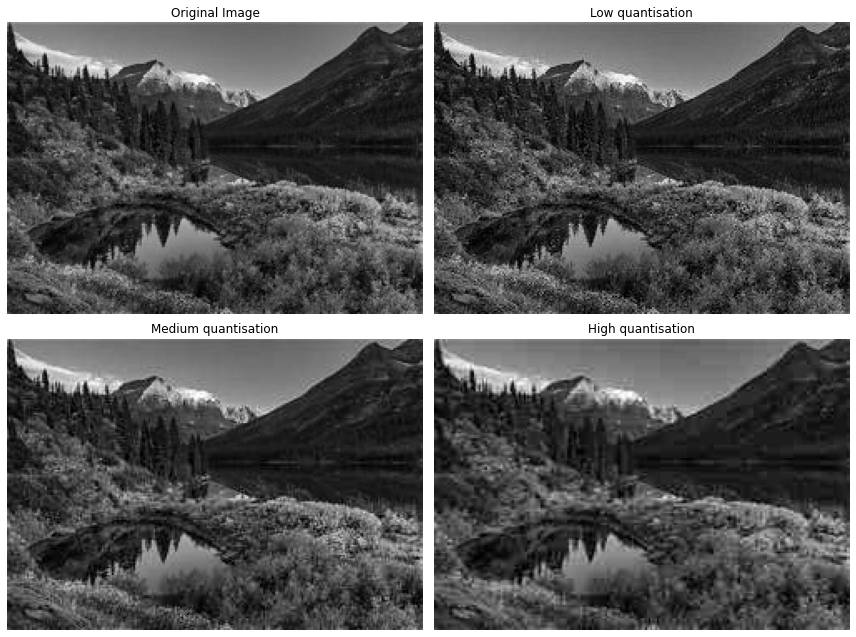

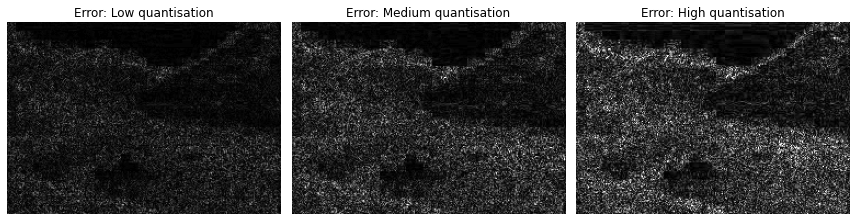

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Load grayscale image
img = cv2.imread("natural_image.jpeg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check natural_image.jpeg")

# Standard JPEG-style luminance quantisation matrix
Q = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)


def jpeg_compress(image, scale):
    # Pad dimensions to multiples of 8
    h, w = image.shape
    pad_h = (8 - h % 8) % 8
    pad_w = (8 - w % 8) % 8

    padded = np.pad(
        image,
        ((0, pad_h), (0, pad_w)),
        mode="edge"
    ).astype(np.float32)

    reconstructed = np.zeros_like(padded)
    quant_matrix = Q * scale

    for y in range(0, padded.shape[0], 8):
        for x in range(0, padded.shape[1], 8):

            # Level shift from [0, 255] to [-128, 127]
            block = padded[y:y+8, x:x+8] - 128

            # Forward DCT
            dct_block = cv2.dct(block)

            # Quantisation
            quantized = np.round(
                dct_block / quant_matrix
            )

            # Dequantisation and inverse DCT
            restored_coefficients = (
                quantized * quant_matrix
            )

            restored_block = cv2.idct(
                restored_coefficients
            ) + 128

            reconstructed[y:y+8, x:x+8] = restored_block

    # Crop padding and convert to valid pixel values
    return np.clip(
        reconstructed[:h, :w], 0, 255
    ).astype(np.uint8)


# Test three quantisation strengths
levels = {
    "Low quantisation": 0.5,
    "Medium quantisation": 1.0,
    "High quantisation": 2.5
}

results = {}

for name, scale in levels.items():
    restored = jpeg_compress(img, scale)

    psnr_value = peak_signal_noise_ratio(
        img, restored, data_range=255
    )

    ssim_value = structural_similarity(
        img, restored, data_range=255
    )

    results[name] = restored

    print(f"\n{name} (scale={scale})")
    print(f"PSNR: {psnr_value:.2f} dB")
    print(f"SSIM: {ssim_value:.4f}")

# Display original and reconstructed images
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")

for ax, (name, restored) in zip(
    axes.flat[1:], results.items()
):
    ax.imshow(restored, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Display absolute error maps
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, restored) in zip(
    axes, results.items()
):
    error = np.abs(
        img.astype(np.int16) -
        restored.astype(np.int16)
    )

    ax.imshow(error, cmap="gray", vmin=0, vmax=50)
    ax.set_title("Error: " + name)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Problem 5: Texture-Based Segmentation using GLCM Features

In [11]:
pip install opencv-python numpy matplotlib scikit-image scikit-learn

Note: you may need to restart the kernel to use updated packages.


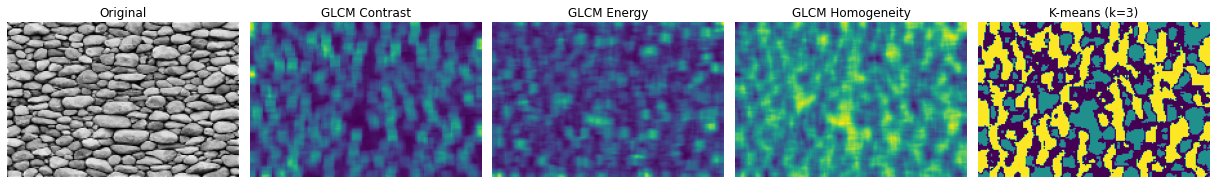

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load image
img = cv2.imread("texture_image.jpeg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Image not found")

# Resize to reduce computation time
img = cv2.resize(img, (180, 120))

# Quantise to 16 gray levels
levels = 16
quantized = (img.astype(np.uint16) * levels // 256).astype(np.uint8)

# Extract local GLCM features
window = 9
pad = window // 2
padded = np.pad(quantized, pad, mode="reflect")

features = np.zeros((img.shape[0], img.shape[1], 3),
                    dtype=np.float32)

for y in range(img.shape[0]):
    for x in range(img.shape[1]):

        patch = padded[y:y+window, x:x+window]

        glcm = graycomatrix(
            patch,
            distances=[1],
            angles=[0],
            levels=levels,
            symmetric=True,
            normed=True
        )

        features[y, x, 0] = graycoprops(
            glcm, "contrast"
        )[0, 0]

        features[y, x, 1] = graycoprops(
            glcm, "energy"
        )[0, 0]

        features[y, x, 2] = graycoprops(
            glcm, "homogeneity"
        )[0, 0]

# Standardise features before K-means
X = features.reshape(-1, 3)
X = StandardScaler().fit_transform(X)

# Segment into three clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X).reshape(img.shape)

# Display results
fig, ax = plt.subplots(1, 5, figsize=(17, 4))

ax[0].imshow(img, cmap="gray")
ax[0].set_title("Original")

ax[1].imshow(features[:, :, 0], cmap="viridis")
ax[1].set_title("GLCM Contrast")

ax[2].imshow(features[:, :, 1], cmap="viridis")
ax[2].set_title("GLCM Energy")

ax[3].imshow(features[:, :, 2], cmap="viridis")
ax[3].set_title("GLCM Homogeneity")

ax[4].imshow(labels, cmap="viridis")
ax[4].set_title("K-means (k=3)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Problem 6: Multi-Feature Segmentation for Disease Detection

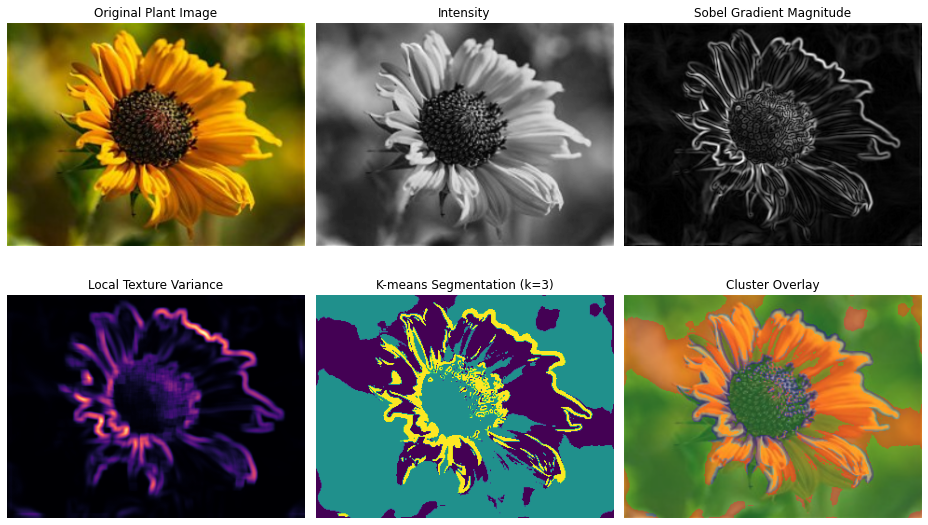


Cluster 0
Mean intensity: 0.561
Mean gradient: 0.092
Mean local variance: 0.061

Cluster 1
Mean intensity: 0.247
Mean gradient: 0.054
Mean local variance: 0.025

Cluster 2
Mean intensity: 0.439
Mean gradient: 0.397
Mean local variance: 0.336


In [8]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load plant image
img = cv2.imread("flower.jpeg")

if img is None:
    raise FileNotFoundError("Image not found")

img = cv2.resize(img, (320, 240))

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_float = gray.astype(np.float32)

# Feature 1: Normalised intensity
intensity = gray_float / 255.0

# Feature 2: Sobel gradient magnitude
blurred = cv2.GaussianBlur(gray, (3, 3), 0)

gx = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)

gradient = cv2.magnitude(gx, gy)
gradient = cv2.normalize(
    gradient, None, 0, 1, cv2.NORM_MINMAX
)

# Feature 3: Local texture variance (9x9 window)
mean = cv2.blur(gray_float, (9, 9))
mean_square = cv2.blur(gray_float ** 2, (9, 9))

variance = np.maximum(mean_square - mean ** 2, 0)
variance = cv2.normalize(
    variance, None, 0, 1, cv2.NORM_MINMAX
)

# Construct a three-feature vector for every pixel
features = np.stack(
    [intensity, gradient, variance], axis=-1
)

X = features.reshape(-1, 3)

# Standardise features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)
segmentation = labels.reshape(gray.shape)

# Display segmentation and individual features
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

axes[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original Plant Image")

axes[0, 1].imshow(intensity, cmap="gray")
axes[0, 1].set_title("Intensity")

axes[0, 2].imshow(gradient, cmap="gray")
axes[0, 2].set_title("Sobel Gradient Magnitude")

axes[1, 0].imshow(variance, cmap="magma")
axes[1, 0].set_title("Local Texture Variance")

axes[1, 1].imshow(segmentation, cmap="viridis")
axes[1, 1].set_title("K-means Segmentation (k=3)")

# Colour overlay to inspect cluster boundaries
colour_map = np.array([
    [255, 80, 80],
    [80, 220, 100],
    [80, 120, 255]
], dtype=np.uint8)

overlay = colour_map[segmentation]
original_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

combined = cv2.addWeighted(
    original_rgb, 0.6, overlay, 0.4, 0
)

axes[1, 2].imshow(combined)
axes[1, 2].set_title("Cluster Overlay")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Print cluster feature averages
for cluster in range(3):
    pixels_in_cluster = features[segmentation == cluster]

    print(f"\nCluster {cluster}")
    print("Mean intensity:",
          round(float(pixels_in_cluster[:, 0].mean()), 3))
    print("Mean gradient:",
          round(float(pixels_in_cluster[:, 1].mean()), 3))
    print("Mean local variance:",
          round(float(pixels_in_cluster[:, 2].mean()), 3))


#### Important: K-means cluster numbers are arbitrary. Cluster 0 is not automatically the diseased region. Inspect the original image, segmentation map, and cluster feature averages to determine which cluster corresponds to suspicious tissue. For a reliable evaluation of disease detection, you also need a manually labelled reference mask.
### Evaluation and observations
#### Which feature contributes most to separating diseased and healthy regions?
#### Feature	Contribution	Limitation
#### Intensity	Separates regions with different brightness or colour-derived grayscale values	Healthy shadows may resemble dark lesions
#### Sobel gradient	Highlights lesion boundaries and abrupt changes	May detect veins, leaf edges, and background boundaries
#### Local texture variance	Helps identify irregular or rough tissue compared with smoother areas	Natural leaf patterns can resemble disease texture

### The most useful feature depends on the image. For brown or yellow lesions against green leaves, intensity may be particularly informative. If lesions have irregular boundaries or texture, gradient magnitude and local variance may provide additional separation.

#### Possible misclassifications and reasons
#### 1. Shadows may be classified as diseased tissue because they have lower intensity.
#### 2. Leaf veins and edges may be grouped with lesions because they have high gradient magnitude.
#### 3. Healthy but naturally textured areas may be classified with diseased tissue due to high local variance.
#### 4. Small lesions may be missed if their features are similar to surrounding healthy tissue.
#### 5. Background pixels may occupy a cluster, leaving the other clusters to divide healthy and diseased tissue imperfectly.
### 4. Conclusion
#### Combining intensity, Sobel gradient magnitude, and local texture variance gives K-means more information than using grayscale intensity alone. Intensity distinguishes brightness differences, gradient magnitude captures boundaries, and local variance describes texture. However, unsupervised clustering identifies visual groups rather than diagnosing disease. Accurate evaluation requires labelled healthy and diseased regions, ideally using metrics such as precision, recall, and intersection over union (IoU).